In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

import os
import sys
from pathlib import Path

# Utils lives under SynEnergy/. This notebook is Analysis/Figure/Motivation/
# Prefer the notebook file path (Cursor/VS Code); fall back to cwd.
_nb_file = globals().get("__vsc_ipynb_file__")
_nb_dir = Path(_nb_file).resolve().parent if _nb_file else Path.cwd().resolve()
synenergy_root = (_nb_dir / ".." / ".." / ".." / "SynEnergy").resolve()
if not (synenergy_root / "Utils").is_dir():
    # cwd may already be SynEnergy (or another parent)
    synenergy_root = None
    for p in [_nb_dir, *_nb_dir.parents]:
        cand = p / "SynEnergy"
        if (cand / "Utils").is_dir():
            synenergy_root = cand
            break
if synenergy_root is None:
    raise RuntimeError(f"Cannot locate SynEnergy/Utils from nb_dir={_nb_dir}, cwd={Path.cwd()}")
if str(synenergy_root) not in sys.path:
    sys.path.insert(0, str(synenergy_root))

import torch
from Utils.context_fid import Context_FID
from Utils.predictive_metric import predictive_score_metrics
import Utils.extreme_anomaly_metric as extreme_anomaly_metric
from Utils.extreme_anomaly_metric import (
    extreme_anomaly_score_metrics,
    extreme_reconstruction_score_metrics,
)


pd.set_option("display.max_rows", None)         # Show all rows
pd.set_option("display.max_columns", None)      # Show all columns
pd.set_option("display.width", None)            # No fixed-width wrap
pd.set_option("display.max_colwidth", None)     # Do not truncate cell values
pd.set_option("display.expand_frame_repr", False)  # Prefer single-line frames

PLOT_DIR = "../../../Analysis/Plot/Experiment/Anomaly_Visualization"

In [3]:
OUT = "../../../SynEnergy/OUTPUT/power"

ori1 = np.load(f"{OUT}/diffusionts/power1/origin_data_norm_power1.npy")
ori2 = np.load(f"{OUT}/diffusionts/power2/origin_data_norm_power2.npy")
ori3 = np.load(f"{OUT}/diffusionts/power3/origin_data_norm_power3.npy")
ori4 = np.load(f"{OUT}/diffusionts/power4/origin_data_norm_power4.npy")
ori5 = np.load(f"{OUT}/diffusionts/power5/origin_data_norm_power5.npy")

gen11 = np.load(f"{OUT}/diffusionts/power1/generate_data_norm_power1.npy")
gen21 = np.load(f"{OUT}/diffusionts/power2/generate_data_norm_power2.npy")
gen31 = np.load(f"{OUT}/diffusionts/power3/generate_data_norm_power3.npy")
gen41 = np.load(f"{OUT}/diffusionts/power4/generate_data_norm_power4.npy")
gen51 = np.load(f"{OUT}/diffusionts/power5/generate_data_norm_power5.npy")

gen12 = np.load(f"{OUT}/controlnet/power_controlnet1/generate_data_norm_power_controlnet1.npy")
gen22 = np.load(f"{OUT}/controlnet/power_controlnet2/generate_data_norm_power_controlnet2.npy")
gen32 = np.load(f"{OUT}/controlnet/power_controlnet3/generate_data_norm_power_controlnet3.npy")
gen42 = np.load(f"{OUT}/controlnet/power_controlnet4/generate_data_norm_power_controlnet4.npy")
gen52 = np.load(f"{OUT}/controlnet/power_controlnet5/generate_data_norm_power_controlnet5.npy")

gen13 = np.load(f"{OUT}/heavydiff/power_heavy1/generate_data_norm_power_heavy1.npy")
gen23 = np.load(f"{OUT}/heavydiff/power_heavy2/generate_data_norm_power_heavy2.npy")
gen33 = np.load(f"{OUT}/heavydiff/power_heavy3/generate_data_norm_power_heavy3.npy")
gen43 = np.load(f"{OUT}/heavydiff/power_heavy4/generate_data_norm_power_heavy4.npy")
gen53 = np.load(f"{OUT}/heavydiff/power_heavy5/generate_data_norm_power_heavy5.npy")

gen14 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet1/generate_data_norm_power_heavy_controlnet1.npy")
gen24 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet2/generate_data_norm_power_heavy_controlnet2.npy")
gen34 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet3/generate_data_norm_power_heavy_controlnet3.npy")
gen44 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet4/generate_data_norm_power_heavy_controlnet4.npy")
gen54 = np.load(f"{OUT}/heavydiffcontrol/power_heavy_controlnet5/generate_data_norm_power_heavy_controlnet5.npy")

## Anomaly Rate

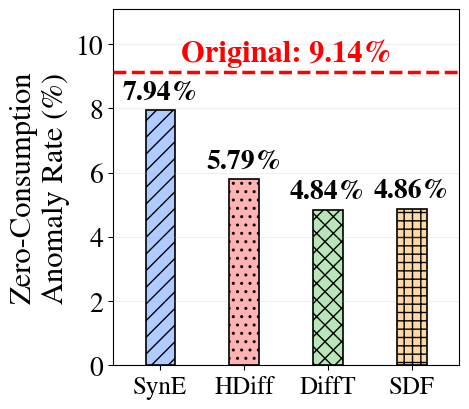

In [4]:
import numpy as np
import matplotlib.pyplot as plt

PLOT_DIR = "../../../Analysis/Plot/Experiment/Anomaly_Visualization"

# 四个方法的 zero rate (%) —— 你来填
rates = [7.94, 5.79, 4.84, 4.86]

labels = ["SynE", "HDiff", "DiffT", "SDF"]
colors = ["#AFCBFF", "#FFB3B3", "#B8E6B8", "#FFD9A8"]
hatches = ["//", "..", "xx", "++"]

fig, ax = plt.subplots(figsize=(5, 4.2))

# 四根柱子，间距与原来两柱风格接近
x = np.array([0.1, 0.72, 1.34, 1.96])
bar_width = 0.22

bars = ax.bar(
    x,
    rates,
    width=bar_width,
    color=colors,
    edgecolor="black",
    linewidth=1.2,
)

for bar, hatch in zip(bars, hatches):
    bar.set_hatch(hatch)

# 柱顶数值
for xi, yi in zip(x, rates):
    ax.text(
        xi,
        yi + 0.18,
        f"{yi:.2f}%",
        ha="center",
        va="bottom",
        fontsize=20,
        fontweight="bold",
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=18, ha="center")

ax.set_ylabel("Zero-Consumption\nAnomaly Rate (%)", fontsize=22)
ax.tick_params(axis="y", labelsize=20)

ori_zero_rate = 9.14
ax.axhline(
    y=ori_zero_rate,
    color="red",
    linestyle="--",
    linewidth=2.5,
    zorder=3,
)

ax.text(
    0.25,
    ori_zero_rate + 0.15,
    f"Original: {ori_zero_rate:.2f}%",
    color="red",
    fontsize=22,
    ha="left",
    va="bottom",
    fontweight="bold",
)

ax.set_ylim(0, 11.1)
ax.grid(axis="y", alpha=0.2)
ax.set_xlim(-0.25, 2.31)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/zero_rate_four_methods.png", dpi=300)
plt.show()

In [5]:
from Experiment.Result_Analysis.anomaly_distribution_metrics import (
    _standardized_residual_batch,
    DEFAULT_TAU,
    DEFAULT_NUM_DAYS,
    DEFAULT_SLOTS_PER_DAY,
    DEFAULT_RESIDUAL_EPS,
    DEFAULT_MIN_SCALE,
)
def to_metric_first_space(data):
    data = np.asarray(data, dtype=np.float64)
    if data.ndim == 2:
        data = data[..., None]
    return _standardized_residual_batch(
        data,
        DEFAULT_NUM_DAYS,        # 30
        DEFAULT_SLOTS_PER_DAY,   # 6
        DEFAULT_RESIDUAL_EPS,    # 1e-6
        DEFAULT_MIN_SCALE,       # 1.0
        True,                    # use_mad_consistency
    )
# 示例
r_ori1 = to_metric_first_space(ori1) 
r_ori2 = to_metric_first_space(ori2)
r_ori3 = to_metric_first_space(ori3)
r_ori4 = to_metric_first_space(ori4)
r_ori5 = to_metric_first_space(ori5)

r_gen11 = to_metric_first_space(gen11)
r_gen21 = to_metric_first_space(gen21)
r_gen31 = to_metric_first_space(gen31)
r_gen41 = to_metric_first_space(gen41)
r_gen51 = to_metric_first_space(gen51)

r_gen12 = to_metric_first_space(gen12)
r_gen22 = to_metric_first_space(gen22)
r_gen32 = to_metric_first_space(gen32)
r_gen42 = to_metric_first_space(gen42)
r_gen52 = to_metric_first_space(gen52)

r_gen13 = to_metric_first_space(gen13)
r_gen23 = to_metric_first_space(gen23)
r_gen33 = to_metric_first_space(gen33)
r_gen43 = to_metric_first_space(gen43)
r_gen53 = to_metric_first_space(gen53)

r_gen14 = to_metric_first_space(gen14)
r_gen24 = to_metric_first_space(gen24)
r_gen34 = to_metric_first_space(gen34)
r_gen44 = to_metric_first_space(gen44)
r_gen54 = to_metric_first_space(gen54)


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# 与 Metric_First 一致
TAU = np.nanquantile(np.abs(r_ori1), 0.90)

def to_2d_r(arr):
    """(N, T, 1) or (N, T) residual -> (N, T)"""
    return np.asarray(arr, dtype=float).squeeze(-1)

def residual_anomaly_mask(r_batch, tau=TAU):
    """|r| > tau"""
    return np.abs(to_2d_r(r_batch)) > float(tau)

def extract_event_lengths_from_mask(mask_2d):
    event_lengths = []
    for mask in mask_2d:
        padded = np.pad(mask.astype(int), (1, 1), constant_values=0)
        transitions = np.diff(padded)
        starts = np.where(transitions == 1)[0]
        ends = np.where(transitions == -1)[0]
        event_lengths.extend(ends - starts)
    return np.asarray(event_lengths, dtype=int)

def pool_residual_event_lengths(r_list, tau=TAU):
    """5 runs: pool event lengths from |r|>tau masks."""
    lengths = []
    for r in r_list:
        mask = residual_anomaly_mask(r, tau=tau)
        lengths.append(extract_event_lengths_from_mask(mask))
    return np.concatenate(lengths)


def _count_k_formatter(x, pos):
    if x == 0:
        return "0"
    if abs(x) >= 1000:
        v = x / 1000.0
        return f"{v:.0f}k" if abs(v - round(v)) < 1e-6 else f"{v:.1f}k"
    return f"{int(x)}"
def plot_duration_hist(ori_lengths, gen_lengths, title, label1, label2, save_path=None):
    bin_width = 1
    x_min, x_max = 0, 7
    # 中心在 1, 2, 3, ...：边界 0.5, 1.5, 2.5, ...
    bin_centers = np.arange(x_min + 1, x_max + 1, bin_width)   # 1,2,...,7
    bins = np.arange(x_min + 0.5, x_max + 0.5 + bin_width, bin_width)  # 0.5,...,7.5
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ax.hist(
        ori_lengths,
        bins=bins,
        alpha=0.55,
        color="#AFCBFF",
        edgecolor="black",
        linewidth=1.0,
        hatch="//",
        label=label1,
    )
    ax.hist(
        gen_lengths,
        bins=bins,
        alpha=0.55,
        color="#FFB3B3",
        edgecolor="black",
        linewidth=1.0,
        hatch="..",
        label=label2,
    )
    ax.set_xlim(x_min, x_max + 1)   # 略宽一点，让 7 的柱子完整显示
    ax.set_xticks(bin_centers)      # 1,2,...,7 每个都显示
    ax.set_xticklabels([str(int(x)) for x in bin_centers], fontsize=22)
    ax.set_xlabel("Anomaly Event Duration", fontsize=25)
    ax.set_ylabel("Count", fontsize=25)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(_count_k_formatter))
    ax.tick_params(axis="y", labelsize=22)
    ax.legend(loc="upper right", bbox_to_anchor=(1.05, 1.03), fontsize=20, frameon=False)
    ax.grid(axis="y", alpha=0.2)
    #ax.set_title(title, fontsize=18)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300)
    plt.show()

# ---------- 使用已转换的 residual（r_ori*, r_gen*）----------
ori_list = [globals()[f"r_ori{i}"] for i in range(1, 6)]
gen_diff_list = [globals()[f"r_gen{i}1"] for i in range(1, 6)]   # DiffusionTS
gen_cn_list = [globals()[f"r_gen{i}2"] for i in range(1, 6)]     # ControlNet
gen_heavy_list = [globals()[f"r_gen{i}3"] for i in range(1, 6)] # Heavy
gen_heavy_controlnet_list = [globals()[f"r_gen{i}4"] for i in range(1, 6)] # Heavy ControlNet

print(f"Anomaly threshold: |r| > TAU = {TAU}  (same as Metric_First)")

# pooled event lengths（5-run）
ori_event_lengths = pool_residual_event_lengths(ori_list, tau=TAU)
gen_diff_lengths = pool_residual_event_lengths(gen_diff_list, tau=TAU)
gen_cn_lengths = pool_residual_event_lengths(gen_cn_list, tau=TAU)
gen_heavy_lengths = pool_residual_event_lengths(gen_heavy_list, tau=TAU)
gen_heavy_controlnet_lengths = pool_residual_event_lengths(gen_heavy_controlnet_list, tau=TAU)

summary = pd.DataFrame({
    "series": ["ori", "diffusionts", "controlnet", "heavy", "heavy_controlnet"],
    "n_events": [len(ori_event_lengths), len(gen_diff_lengths), len(gen_cn_lengths), len(gen_heavy_lengths), len(gen_heavy_controlnet_lengths)],
    "mean_duration": [
        ori_event_lengths.mean(),
        gen_diff_lengths.mean(),
        gen_cn_lengths.mean(),
        gen_heavy_lengths.mean(),
        gen_heavy_controlnet_lengths.mean(),
    ],
    "median_duration": [
        np.median(ori_event_lengths),
        np.median(gen_diff_lengths),
        np.median(gen_cn_lengths),
        np.median(gen_heavy_lengths),
        np.median(gen_heavy_controlnet_lengths),
    ],
})
display(summary)

Anomaly threshold: |r| > TAU = 0.11283458769321442  (same as Metric_First)


,series,n_events,mean_duration,median_duration
0,ori,504220,1.783825,1.0
1,diffusionts,288574,1.640106,1.0
2,controlnet,460435,1.806752,1.0
3,heavy,338132,1.550643,1.0
4,heavy_controlnet,508527,1.724762,1.0


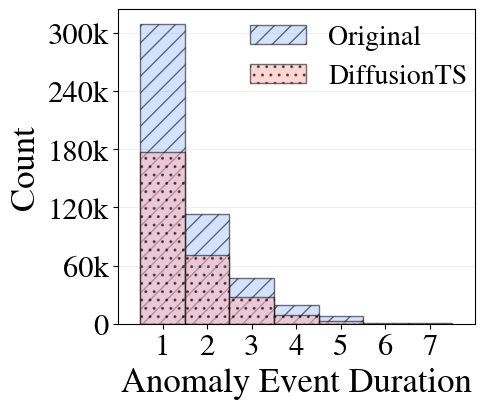

In [7]:
plot_duration_hist(
    ori_event_lengths,
    gen_diff_lengths,
    title=f"Ori vs DiffusionTS (|r|>{TAU}, 5-run pooled)",  
    label1="Original",
    label2="DiffusionTS",
    save_path="../../../Analysis/Plot/Experiment/Anomaly_Visualization/anomaly_duration_diffusionTS.png",
)

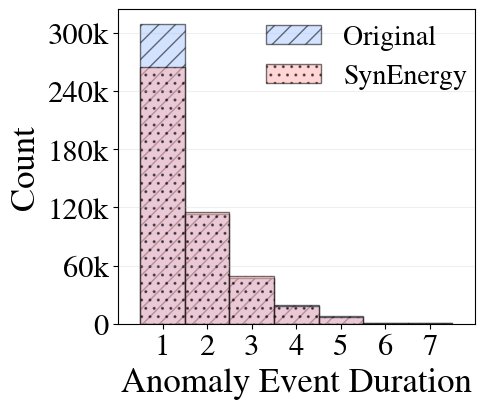

In [8]:
plot_duration_hist(
    ori_event_lengths,
    gen_cn_lengths,
    label1="Original",
    label2="SynEnergy",
    title=f"Ori vs SynEnergy (|r|>{TAU}, 5-run pooled)",
    save_path="../../../Analysis/Plot/Experiment/Anomaly_Visualization/anomaly_duration_SynEnergy.png",
)

In [9]:
import numpy as np
import pandas as pd

# 与 Metric_First 一致
TAU = np.nanquantile(np.abs(r_ori1), 0.90)

def to_2d_r(arr):
    """(N, T, 1) or (N, T) residual -> (N, T)"""
    return np.asarray(arr, dtype=float).squeeze(-1)

def residual_anomaly_mask(r_batch, tau=TAU):
    """|r| > tau"""
    return np.abs(to_2d_r(r_batch)) > float(tau)

def extract_event_lengths_from_mask(mask_2d):
    event_lengths = []
    for mask in mask_2d:
        padded = np.pad(mask.astype(int), (1, 1), constant_values=0)
        transitions = np.diff(padded)
        starts = np.where(transitions == 1)[0]
        ends = np.where(transitions == -1)[0]
        event_lengths.extend(ends - starts)
    return np.asarray(event_lengths, dtype=int)

def per_run_residual_event_lengths(r_list, tau=TAU):
    """每个 run 单独返回 event lengths，不 pool。"""
    return [
        extract_event_lengths_from_mask(residual_anomaly_mask(r, tau=tau))
        for r in r_list
    ]

# ---------- 使用已转换的 residual（r_ori*, r_gen*）----------
ori_list = [globals()[f"r_ori{i}"] for i in range(1, 6)]
gen_diff_list = [globals()[f"r_gen{i}1"] for i in range(1, 6)]      # DiffusionTS
gen_cn_list = [globals()[f"r_gen{i}2"] for i in range(1, 6)]        # ControlNet
gen_heavy_list = [globals()[f"r_gen{i}3"] for i in range(1, 6)]     # Heavy
gen_heavy_controlnet_list = [globals()[f"r_gen{i}4"] for i in range(1, 6)]  # Heavy ControlNet

print(f"Anomaly threshold: |r| > TAU = {TAU}  (same as Metric_First)")

# 每个都是长度为 5 的 list；ori_event_lengths[i] 是第 i 个 run 的所有事件时长
ori_event_lengths = per_run_residual_event_lengths(ori_list, tau=TAU)
gen_diff_lengths = per_run_residual_event_lengths(gen_diff_list, tau=TAU)
gen_cn_lengths = per_run_residual_event_lengths(gen_cn_list, tau=TAU)
gen_heavy_lengths = per_run_residual_event_lengths(gen_heavy_list, tau=TAU)
gen_heavy_controlnet_lengths = per_run_residual_event_lengths(gen_heavy_controlnet_list, tau=TAU)

# 用法示例：
# ori_event_lengths[0]  -> power1 的所有异常事件时长
# ori_event_lengths[4]  -> power5 的所有异常事件时长

Anomaly threshold: |r| > TAU = 0.11283458769321442  (same as Metric_First)


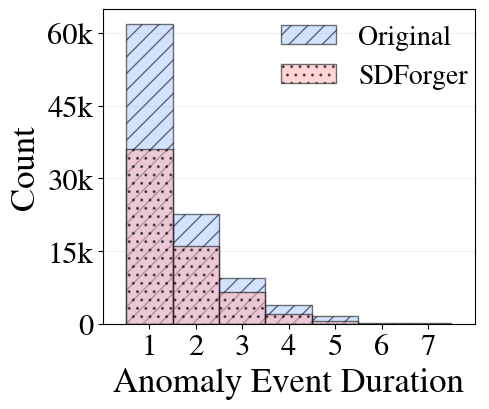

In [53]:
plot_duration_hist(
    ori_event_lengths[0],
    gen_diff_lengths[0],
    label1="Original",
    label2="SDForger",
    title=f"Ori vs SDForger (|r|>{TAU}, 5-run pooled)",
    save_path="../../../Analysis/Plot/Experiment/Anomaly_Visualization/anomaly_duration_SDForger.png",
)

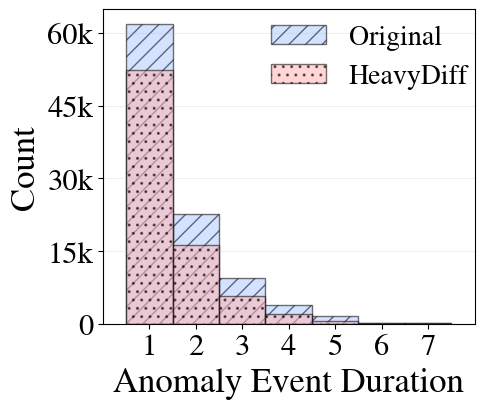

In [54]:
plot_duration_hist(
    ori_event_lengths[3],
    gen_heavy_lengths[3],
    label1="Original",
    label2="HeavyDiff",
    title=f"Ori vs HeavyDiff (|r|>{TAU}, 5-run pooled)",
    save_path="../../../Analysis/Plot/Experiment/Anomaly_Visualization/anomaly_duration_heavyDiff.png",
)

## Figure 3

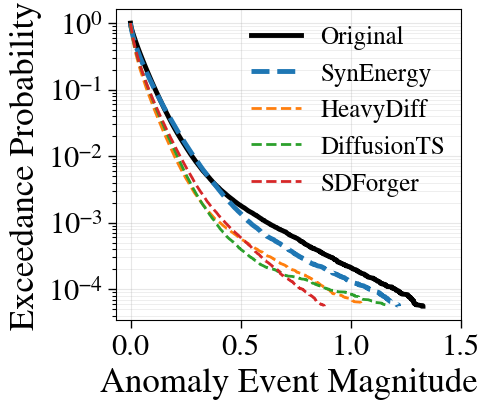

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
PLOT_DIR = "../../../Analysis/Plot/Experiment/Anomaly_Visualization"
XLABEL = "Anomaly Event Magnitude"
YLABEL = "Exceedance Probability"
def to_2d_r(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr.squeeze(-1)
    return arr
def extract_magnitudes(data):
    values = np.asarray(data, dtype=float).reshape(-1)
    values = values[np.isfinite(values)]
    return np.abs(values)
def empirical_ccdf(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.array([]), np.array([])
    x = np.sort(values)
    n = len(x)
    return x, (n - np.arange(n)) / n
def _stable_tail_mask(x, ccdf, display_threshold, min_p):
    return (x >= display_threshold) & (ccdf >= min_p)
def plot_residual_magnitude_ccdf_multi(
    ori,
    ours,
    heavyd,
    difft,
    sdf,
    display_threshold=0.0,
    min_tail_count=100,
    xlabel=XLABEL,
    ylabel=YLABEL,
    title=None,
    save_path=None,
):
    """
  ori, ours, heavyd, difft, sdf: 单个 run 的 residual 数组
    """
    fig, ax = plt.subplots(figsize=(5, 4.2))
    series = [
        ("Original", ori, dict(color="black", linestyle="-", linewidth=3.5)),
        ("SynEnergy",          ours, dict(color="#1f77b4", linestyle="--", linewidth=3.5)),
        ("HeavyDiff",        heavyd, dict(color="#ff7f0e", linestyle="--", linewidth=2)),
        ("DiffusionTS",         difft, dict(color="#2ca02c", linestyle="--", linewidth=2)),
        ("SDForger",           sdf, dict(color="#d62728", linestyle="--", linewidth=2)),
    ]
    for label, data, style in series:
        mag = extract_magnitudes(data)
        x, ccdf = empirical_ccdf(mag)
        min_p = min_tail_count / len(mag)
        mask = _stable_tail_mask(x, ccdf, display_threshold, min_p)
        ax.plot(x[mask], ccdf[mask], label=label, **style)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(xlabel, fontsize=25)
    ax.set_ylabel(ylabel, fontsize=25)
    ax.set_xticks([0, 0.5, 1.0, 1.5])
    ax.tick_params(axis="both", which="major", labelsize=22, length=6, width=1.0)
    ax.tick_params(axis="y", which="minor", length=3, width=0.8, left=True, right=False)
    ax.legend(loc="upper right", bbox_to_anchor=(1.02, 1.02), fontsize=18, frameon=False)
    ax.grid(which="major", axis="both", alpha=0.30, linewidth=0.8)
    ax.grid(which="minor", axis="y", alpha=0.30, linewidth=0.5)
    if display_threshold > 0:
        ax.set_xlim(left=display_threshold)
    if title is not None:
        ax.set_title(title, fontsize=18)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
# ---------- 每个 run 单独保存 residual（长度均为 5）----------
ori_runs = [globals()[f"r_ori{i}"] for i in range(1, 6)]
ours_runs = [globals()[f"r_gen{i}4"] for i in range(1, 6)]      # heavy_controlnet
heavyd_runs = [globals()[f"r_gen{i}3"] for i in range(1, 6)]  # heavy
difft_runs = [globals()[f"r_gen{i}1"] for i in range(1, 6)]    # diffusionTS
sdf_runs = [globals()[f"r_gen{i}2"] for i in range(1, 6)]      # controlnet
# 用法示例：
# ori_runs[0], ours_runs[0], heavyd_runs[0], difft_runs[0], sdf_runs[0] -> power1
# ori_runs[4], ours_runs[4], heavyd_runs[4], difft_runs[4], sdf_runs[4] -> power5

plot_residual_magnitude_ccdf_multi(
    ori_runs[0],
    ours_runs[0],
    difft_runs[2],
    heavyd_runs[2],
    difft_runs[4],
    min_tail_count=100,
    save_path = "../../../Analysis/Plot/Experiment/Anomaly_Visualization/anomaly_magnitude.png",
    )

## Figure Four

===== Run 1 =====


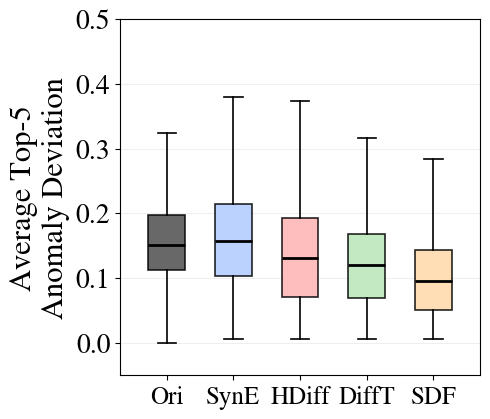

Ori          mean: 0.1655, median: 0.1514
SynE         mean: 0.1647, median: 0.1570
HDiff        mean: 0.1450, median: 0.1305
DiffT        mean: 0.1232, median: 0.1207
SDF          mean: 0.1073, median: 0.0958


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from numpy.lib.stride_tricks import sliding_window_view

PLOT_DIR = "../../../Analysis/Plot/Experiment/Anomaly_Visualization"
radius = 3
top_n = 5

def to_2d_r(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr.squeeze(-1)
    return arr

def surrounding_median_baseline(data, radius=2):
    data = np.asarray(data, dtype=float)
    if data.ndim != 2:
        raise ValueError("data must be a 2D array.")
    if radius < 1:
        raise ValueError("radius must be at least 1.")
    window_size = 2 * radius + 1
    padded = np.pad(data, pad_width=((0, 0), (radius, radius)), mode="edge")
    windows = sliding_window_view(padded, window_shape=window_size, axis=1)
    surrounding_values = np.concatenate(
        [windows[:, :, :radius], windows[:, :, radius + 1:]],
        axis=-1,
    )
    return np.nanmedian(surrounding_values, axis=-1)

def top_n_mean(values, n=5):
    values = np.asarray(values, dtype=float)
    if values.ndim != 2:
        raise ValueError("values must be a 2D array.")
    num_points = values.shape[1]
    if not 1 <= n <= num_points:
        raise ValueError(f"n must be between 1 and {num_points}.")
    safe_values = np.where(np.isfinite(values), values, -np.inf)
    top_values = np.partition(safe_values, kth=num_points - n, axis=1)[:, -n:]
    top_values[top_values == -np.inf] = np.nan
    return np.nanmean(top_values, axis=1)

def compute_top_n_local_deviation(data_2d, radius=5, top_n=10):
    baseline = surrounding_median_baseline(data_2d, radius=radius)
    abs_dev = np.abs(data_2d - baseline)
    top_n_dev = top_n_mean(abs_dev, n=top_n)
    return top_n_dev[np.isfinite(top_n_dev)]

def per_run_top_n_local_deviation(r_list, radius=3, top_n=5):
    return [
        compute_top_n_local_deviation(to_2d_r(r), radius=radius, top_n=top_n)
        for r in r_list
    ]

def plot_topn_boxplot_one_run(
    ori_vals,
    ours_vals,
    heavyd_vals,
    difft_vals,
    sdf_vals,
    top_n,
    run_idx,
    title=None,
    save_path=None,
    ylim=None,
    showfliers=False,
    box_width=0.55,
):
    """
    单个 run：一张图里 5 个 box
    Original + SynEnergy + HeavyDiff + DiffusionTS + SDForger
    """

    labels = ["Ori","SynE", "HDiff", "DiffT", "SDF"]
    data = [ori_vals, ours_vals, heavyd_vals, difft_vals, sdf_vals]
    colors = ["#4D4D4D","#AFCBFF", "#FFB3B3", "#B8E6B8", "#FFD9A8"]
    positions = np.arange(1, 6)

    fig, ax = plt.subplots(figsize=(5, 4.2))
    box = ax.boxplot(
        data,
        positions=positions,
        widths=box_width,
        patch_artist=True,
        showfliers=showfliers,
        medianprops={"color": "black", "linewidth": 2.0},
        boxprops={"edgecolor": "black", "linewidth": 1.2},
        whiskerprops={"color": "black", "linewidth": 1.2},
        capprops={"color": "black", "linewidth": 1.2},
    )

    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, fontsize=18, ha="center")
    ax.set_ylabel(f"Average Top-{top_n}\nAnomaly Deviation", fontsize=22)
    ax.tick_params(axis="y", labelsize=20)
    ax.grid(axis="y", alpha=0.2)

    if ylim is not None:
        ax.set_ylim(ylim)
    # if title is None:
    #     title = f"Run {run_idx + 1}"
    ax.set_title(title, fontsize=18)

    ax.set_xlim(0.3, 5.7)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    for label, vals in zip(labels, data):
        print(f"{label:12s} mean: {np.mean(vals):.4f}, median: {np.median(vals):.4f}")

# ---------- 每个 run 单独保存 residual（长度均为 5）----------
ori_runs = [globals()[f"r_ori{i}"] for i in range(1, 6)]
ours_runs = [globals()[f"r_gen{i}4"] for i in range(1, 6)]      # SynEnergy
heavyd_runs = [globals()[f"r_gen{i}3"] for i in range(1, 6)]    # HeavyDiff
difft_runs = [globals()[f"r_gen{i}1"] for i in range(1, 6)]     # DiffusionTS
sdf_runs = [globals()[f"r_gen{i}2"] for i in range(1, 6)]       # SDForger

ori_top_n_deviation = per_run_top_n_local_deviation(ori_runs, radius=radius, top_n=top_n)
ours_top_n_deviation = per_run_top_n_local_deviation(ours_runs, radius=radius, top_n=top_n)
heavyd_top_n_deviation = per_run_top_n_local_deviation(heavyd_runs, radius=radius, top_n=top_n)
difft_top_n_deviation = per_run_top_n_local_deviation(difft_runs, radius=radius, top_n=top_n)
sdf_top_n_deviation = per_run_top_n_local_deviation(sdf_runs, radius=radius, top_n=top_n)

# 5 张图：每张对应一个 run
i=0
print(f"===== Run {i + 1} =====")
plot_topn_boxplot_one_run(
    ori_top_n_deviation[i],
    ours_top_n_deviation[i],
    sdf_top_n_deviation[i],
    heavyd_top_n_deviation[i],
    difft_top_n_deviation[i],
    top_n=top_n,
    run_idx=i,
    ylim=(-0.05, 0.5),
    showfliers=False,
    save_path=f"{PLOT_DIR}/anomaly_deviation_boxplot.png",
)

## Figure 5

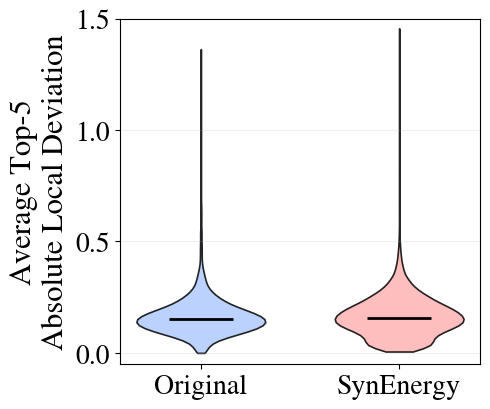

===== Violin Plot Summary =====
Original mean: 0.1655, median: 0.1514
Generated mean: 0.1647, median: 0.1570
Original Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.1035, Q3: 0.2137



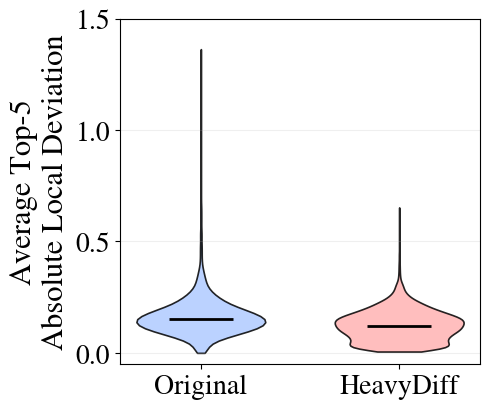

===== Violin Plot Summary =====
Original mean: 0.1655, median: 0.1514
Generated mean: 0.1232, median: 0.1207
Original Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.0687, Q3: 0.1679



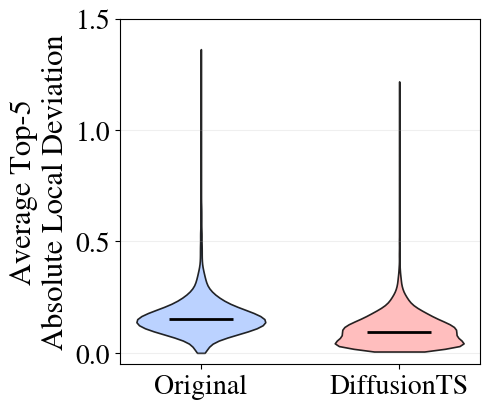

===== Violin Plot Summary =====
Original mean: 0.1655, median: 0.1514
Generated mean: 0.1073, median: 0.0958
Original Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.0501, Q3: 0.1440



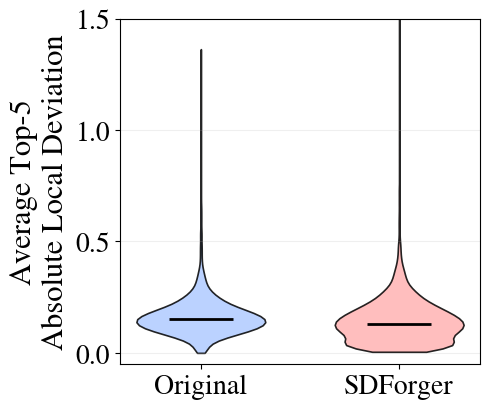

===== Violin Plot Summary =====
Original mean: 0.1655, median: 0.1514
Generated mean: 0.1450, median: 0.1305
Original Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.0712, Q3: 0.1923



In [11]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

PLOT_DIR = "../../../Analysis/Plot/Experiment/Anomaly_Visualization"
radius = 3
top_n = 5

def to_2d_r(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr.squeeze(-1)
    return arr

def surrounding_median_baseline(data, radius=2):
    data = np.asarray(data, dtype=float)
    if data.ndim != 2:
        raise ValueError("data must be a 2D array.")
    if radius < 1:
        raise ValueError("radius must be at least 1.")
    window_size = 2 * radius + 1
    padded = np.pad(data, pad_width=((0, 0), (radius, radius)), mode="edge")
    windows = sliding_window_view(padded, window_shape=window_size, axis=1)
    surrounding_values = np.concatenate(
        [windows[:, :, :radius], windows[:, :, radius + 1:]],
        axis=-1,
    )
    return np.nanmedian(surrounding_values, axis=-1)

def top_n_mean(values, n=5):
    values = np.asarray(values, dtype=float)
    if values.ndim != 2:
        raise ValueError("values must be a 2D array.")
    num_points = values.shape[1]
    if not 1 <= n <= num_points:
        raise ValueError(f"n must be between 1 and {num_points}.")
    safe_values = np.where(np.isfinite(values), values, -np.inf)
    top_values = np.partition(safe_values, kth=num_points - n, axis=1)[:, -n:]
    top_values[top_values == -np.inf] = np.nan
    return np.nanmean(top_values, axis=1)

def compute_top_n_local_deviation(data_2d, radius=5, top_n=10):
    baseline = surrounding_median_baseline(data_2d, radius=radius)
    abs_dev = np.abs(data_2d - baseline)
    top_n_dev = top_n_mean(abs_dev, n=top_n)
    return top_n_dev[np.isfinite(top_n_dev)]

def per_run_top_n_local_deviation(r_list, radius=3, top_n=5):
    """每个 run 单独计算 top-n local deviation，返回长度为 5 的 list。"""
    return [
        compute_top_n_local_deviation(to_2d_r(r), radius=radius, top_n=top_n)
        for r in r_list
    ]

def plot_topn_violin(ori_vals, gen_vals, top_n, label1=None, label2=None, title=None, save_path=None, ylim=None, bw_method=None):
    fig, ax = plt.subplots(figsize=(5, 4.2))
    violin = ax.violinplot(
        [ori_vals, gen_vals],
        positions=[1, 2],
        widths=0.65,
        showmeans=False,
        showmedians=True,
        showextrema=False,
        bw_method=bw_method,
    )
    for body, color in zip(violin["bodies"], ["#AFCBFF", "#FFB3B3"]):
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.2)
        body.set_alpha(0.85)
    violin["cmedians"].set_color("black")
    violin["cmedians"].set_linewidth(2.0)

    ax.set_xticks([1, 2])
    ax.set_xticklabels([label1, label2], fontsize=22)
    ax.set_ylabel(f"Average Top-{top_n}\nAbsolute Local Deviation", fontsize=22)
    ax.tick_params(axis="both", labelsize=20)
    ax.grid(axis="y", alpha=0.2)
    if ylim is not None:
        ax.set_ylim(ylim)
    if title is not None:
        ax.set_title(title, fontsize=18)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("===== Violin Plot Summary =====")
    print(f"Original mean: {np.mean(ori_vals):.4f}, median: {np.median(ori_vals):.4f}")
    print(f"Generated mean: {np.mean(gen_vals):.4f}, median: {np.median(gen_vals):.4f}")
    print(f"Original Q1: {np.percentile(ori_vals, 25):.4f}, Q3: {np.percentile(ori_vals, 75):.4f}")
    print(f"Generated Q1: {np.percentile(gen_vals, 25):.4f}, Q3: {np.percentile(gen_vals, 75):.4f}\n")

# ---------- 每个 run 单独保存 residual（长度均为 5）----------
ori_runs = [globals()[f"r_ori{i}"] for i in range(1, 6)]
gen_diff_runs = [globals()[f"r_gen{i}1"] for i in range(1, 6)]   # DiffusionTS
gen_cn_runs = [globals()[f"r_gen{i}2"] for i in range(1, 6)]    # ControlNet
gen_heavy_runs = [globals()[f"r_gen{i}3"] for i in range(1, 6)] # Heavy
gen_heavy_cn_runs = [globals()[f"r_gen{i}4"] for i in range(1, 6)]  # Heavy ControlNet

ori_top_n_deviation = per_run_top_n_local_deviation(ori_runs, radius=radius, top_n=top_n)
gen_diff_top_n_deviation = per_run_top_n_local_deviation(gen_diff_runs, radius=radius, top_n=top_n)
gen_cn_top_n_deviation = per_run_top_n_local_deviation(gen_cn_runs, radius=radius, top_n=top_n)
gen_heavy_top_n_deviation = per_run_top_n_local_deviation(gen_heavy_runs, radius=radius, top_n=top_n)
gen_heavy_cn_top_n_deviation = per_run_top_n_local_deviation(gen_heavy_cn_runs, radius=radius, top_n=top_n)

# ---------- 自选 run 索引 [0]~[4] 画图 ----------
# 0 -> power1, 1 -> power2, ..., 4 -> power5

# 示例：power1, Original vs DiffusionTS

# 示例：power1, Original vs DiffusionTS
plot_topn_violin(
    ori_top_n_deviation[0],
    gen_heavy_cn_top_n_deviation[0],
    top_n=top_n,
    label1="Original",
    label2="SynEnergy",
    ylim=(-0.05, 1.5),
    bw_method=0.2,
    save_path=f"{PLOT_DIR}/anomaly_deviation_violinplot_SynEnergy.png",
)

plot_topn_violin(
    ori_top_n_deviation[0],
    gen_heavy_top_n_deviation[0],
    top_n=top_n,
    label1="Original",
    label2="HeavyDiff",
    ylim=(-0.05, 1.5),
    bw_method=0.2,
    save_path=f"{PLOT_DIR}/anomaly_deviation_violinplot_HeavyDiff.png",
)

# 示例：power3, Original vs Heavy ControlNet
plot_topn_violin(
    ori_top_n_deviation[0],
    gen_diff_top_n_deviation[0],
    top_n=top_n,
    label1="Original",
    label2="DiffusionTS",
    ylim=(-0.05, 1.5),
    bw_method=0.2,
    save_path=f"{PLOT_DIR}/anomaly_deviation_violinplot_diffusionTS.png",
)

plot_topn_violin(
    ori_top_n_deviation[0],
    gen_cn_top_n_deviation[0],
    top_n=top_n,
    label1="Original",
    label2="SDForger",
    ylim=(-0.05, 1.5),
    bw_method=0.2,
    save_path=f"{PLOT_DIR}/anomaly_deviation_violinplot_SDForger.png",
)

## Prepare

In [12]:
import importlib
import Experiment.Result_Analysis.anomaly_distribution_metrics as adm
importlib.reload(adm)

from Experiment.Result_Analysis.anomaly_distribution_metrics import (
    compare_anomaly_distribution_multi,
    anomaly_distribution_summary_table,
)


group_ori = [ori1, ori2, ori3, ori4, ori5]
group_diff = [gen11, gen21, gen31, gen41, gen51]
group_cn = [gen12, gen22, gen32, gen42, gen52]
group_heavy = [gen13, gen23, gen33, gen43, gen53]
group_heavy_cn = [gen14, gen24, gen34, gen44, gen54]

group_tables = []
group_results = []
for ori, diff, cn, heavy, heavy_cn in zip(
    group_ori,
    group_diff,
    group_cn,
    group_heavy,
    group_heavy_cn,
):
    baselines = {
        "diff": diff,
        "cn": cn,
        "heavy": heavy,
        "heavy_cn": heavy_cn,
    }
    result = compare_anomaly_distribution_multi(
        ori,
        baselines,
        tau=0.12,
        store_pooled_arrays=True,
    )
    group_results.append(result)
    tbl = anomaly_distribution_summary_table(result, include_ori=True)
    group_tables.append(tbl)
    display(tbl)

anomaly_summary_table = pd.concat(group_tables).groupby(level=0).mean()
display(anomaly_summary_table)

,anomaly_rate_w1,anomaly_rate_gen_mean,event_count_w1,event_count_gen_mean,mean_abs_on_anom_w1,mean_abs_on_anom_gen_mean,pos_ratio_w1,pos_ratio_gen_mean,anomaly_energy_w1,anomaly_energy_gen_mean,longest_run_w1,longest_run_gen_mean,w1_abs_r,w1_abs_r_anom
baseline,,,,,,,,,,,,,,
ori,0.000000,0.088797,0.0000,9.0855,0.000000,0.170450,0.000000,0.658165,0.000000,0.790674,0.0000,3.2926,0.000000,0.000000
diff,0.038541,0.050263,3.6062,5.4793,0.007904,0.162545,0.023926,0.646390,0.415596,0.378206,1.6225,1.6701,0.011827,0.012556
cn,0.011011,0.083984,1.4179,8.8210,0.004090,0.173651,0.019398,0.677563,0.106650,0.746001,0.7530,2.5396,0.003569,0.003092
heavy,0.043033,0.045764,3.5696,5.5159,0.002750,0.168806,0.138897,0.797062,0.486306,0.304368,1.6834,1.6092,0.015512,0.016772
heavy_cn,0.006781,0.086297,1.0872,9.2837,0.009710,0.179304,0.085048,0.743213,0.110200,0.756888,0.7288,2.5638,0.004058,0.006448


,anomaly_rate_w1,anomaly_rate_gen_mean,event_count_w1,event_count_gen_mean,mean_abs_on_anom_w1,mean_abs_on_anom_gen_mean,pos_ratio_w1,pos_ratio_gen_mean,anomaly_energy_w1,anomaly_energy_gen_mean,longest_run_w1,longest_run_gen_mean,w1_abs_r,w1_abs_r_anom
baseline,,,,,,,,,,,,,,
ori,0.000000,0.088797,0.0000,9.0855,0.000000,0.170450,0.000000,0.658165,0.000000,0.790674,0.0000,3.2926,0.000000,0.000000
diff,0.042792,0.046015,3.9079,5.1790,0.008543,0.161912,0.016164,0.654832,0.449148,0.341526,1.8247,1.4679,0.015377,0.012432
cn,0.012928,0.086184,1.7372,8.9053,0.011785,0.182108,0.042247,0.700411,0.252162,0.977978,0.8231,2.4859,0.008697,0.018959
heavy,0.040648,0.048159,3.4720,5.6137,0.006076,0.164374,0.109508,0.767672,0.416456,0.374293,1.7757,1.5169,0.015209,0.009270
heavy_cn,0.032776,0.056028,2.9411,6.1444,0.004335,0.166123,0.083501,0.741665,0.353422,0.440131,1.4319,1.8607,0.011779,0.007467


,anomaly_rate_w1,anomaly_rate_gen_mean,event_count_w1,event_count_gen_mean,mean_abs_on_anom_w1,mean_abs_on_anom_gen_mean,pos_ratio_w1,pos_ratio_gen_mean,anomaly_energy_w1,anomaly_energy_gen_mean,longest_run_w1,longest_run_gen_mean,w1_abs_r,w1_abs_r_anom
baseline,,,,,,,,,,,,,,
ori,0.000000,0.088797,0.0000,9.0855,0.000000,0.170450,0.000000,0.658165,0.000000,0.790674,0.0000,3.2926,0.000000,0.000000
diff,0.048477,0.040320,4.4785,4.6070,0.006720,0.163729,0.018927,0.668885,0.483846,0.306829,1.9240,1.3686,0.017299,0.011317
cn,0.014872,0.089912,1.6646,8.8883,0.008827,0.179177,0.055896,0.610231,0.283019,1.011712,0.6168,2.6758,0.004715,0.015523
heavy,0.039925,0.048872,3.2703,5.8168,0.002220,0.168318,0.115808,0.773972,0.441844,0.351580,1.6427,1.6499,0.014447,0.013816
heavy_cn,0.010391,0.092213,1.1888,9.6301,0.008626,0.178976,0.098964,0.757128,0.121123,0.856811,0.2316,3.0730,0.003308,0.006013


,anomaly_rate_w1,anomaly_rate_gen_mean,event_count_w1,event_count_gen_mean,mean_abs_on_anom_w1,mean_abs_on_anom_gen_mean,pos_ratio_w1,pos_ratio_gen_mean,anomaly_energy_w1,anomaly_energy_gen_mean,longest_run_w1,longest_run_gen_mean,w1_abs_r,w1_abs_r_anom
baseline,,,,,,,,,,,,,,
ori,0.000000,0.088797,0.0000,9.0855,0.000000,0.170450,0.000000,0.658165,0.000000,0.790674,0.0000,3.2926,0.000000,0.000000
diff,0.047226,0.041572,4.3846,4.7009,0.005503,0.164953,0.030903,0.689067,0.493561,0.297114,1.6921,1.6005,0.016714,0.013935
cn,0.010631,0.086300,1.2499,8.6186,0.012121,0.181601,0.034077,0.692242,0.182867,0.771428,0.3014,3.1016,0.006786,0.009231
heavy,0.029967,0.058830,2.1474,6.9381,0.004834,0.165616,0.111102,0.769267,0.359547,0.431128,1.4048,1.8878,0.010005,0.012166
heavy_cn,0.020769,0.107836,2.6696,11.5273,0.014417,0.184696,0.097801,0.755966,0.322985,1.108465,0.4728,2.8270,0.005250,0.012913


,anomaly_rate_w1,anomaly_rate_gen_mean,event_count_w1,event_count_gen_mean,mean_abs_on_anom_w1,mean_abs_on_anom_gen_mean,pos_ratio_w1,pos_ratio_gen_mean,anomaly_energy_w1,anomaly_energy_gen_mean,longest_run_w1,longest_run_gen_mean,w1_abs_r,w1_abs_r_anom
baseline,,,,,,,,,,,,,,
ori,0.000000,0.088797,0.0000,9.0855,0.000000,0.170450,0.000000,0.658165,0.000000,0.790674,0.0000,3.2926,0.000000,0.000000
diff,0.036698,0.052102,3.3348,5.7507,0.003337,0.169881,0.011912,0.667420,0.399354,0.391320,1.6562,1.6364,0.013167,0.008694
cn,0.017971,0.071034,2.1758,7.0983,0.012301,0.182672,0.053444,0.711609,0.179371,0.687152,0.8465,2.4461,0.011374,0.006605
heavy,0.035048,0.053768,2.7876,6.2979,0.004035,0.170564,0.128288,0.786452,0.405109,0.398607,1.4043,1.8883,0.013235,0.010564
heavy_cn,0.009695,0.096297,1.1745,10.0642,0.014748,0.185194,0.097733,0.755897,0.407602,1.195806,0.2157,3.0925,0.006177,0.020490


,anomaly_rate_w1,anomaly_rate_gen_mean,event_count_w1,event_count_gen_mean,mean_abs_on_anom_w1,mean_abs_on_anom_gen_mean,pos_ratio_w1,pos_ratio_gen_mean,anomaly_energy_w1,anomaly_energy_gen_mean,longest_run_w1,longest_run_gen_mean,w1_abs_r,w1_abs_r_anom
baseline,,,,,,,,,,,,,,
cn,0.013482,0.083483,1.64908,8.46630,0.009825,0.179842,0.041012,0.678411,0.200814,0.838854,0.66816,2.64980,0.007028,0.010682
diff,0.042747,0.046054,3.94240,5.14338,0.006401,0.164604,0.020366,0.665319,0.448301,0.342999,1.74390,1.54870,0.014877,0.011787
heavy,0.037724,0.051079,3.04938,6.03648,0.003983,0.167535,0.120720,0.778885,0.421852,0.371995,1.58218,1.71042,0.013682,0.012518
heavy_cn,0.016082,0.087734,1.81224,9.32994,0.010367,0.178859,0.092609,0.750774,0.263067,0.871620,0.61616,2.68340,0.006114,0.010666
ori,0.000000,0.088797,0.00000,9.08550,0.000000,0.170450,0.000000,0.658165,0.000000,0.790674,0.00000,3.29260,0.000000,0.000000


In [14]:
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

ORI_COLOR = "#2166ac"
BASELINE_COLORS = ("#b2182b", "#fdae61", "#4daf4a", "#984ea3", "#7570b3")
FEATURE_KEYS = adm.SUMMARY_TABLE_FEATURE_KEYS


def _finite_values(x):
    v = np.asarray(x, dtype=np.float64).ravel()
    return v[np.isfinite(v)]


def _format_float(x, digits=4):
    if isinstance(x, float) and (np.isnan(x) or np.isinf(x)):
        return "nan"
    return f"{float(x):.{digits}f}"


def _subsample_1d(x, max_points, rng):
    v = _finite_values(x)
    if v.size <= max_points:
        return v
    idx = rng.choice(v.size, size=max_points, replace=False)
    return v[idx]


def plot_feature_marginal(
    result,
    feature_key,
    baseline_names,
    *,
    bins=40,
    kde=True,
    log_energy=True,
    figsize=(5, 4.2),
    save_path=None,
):
    """单特征边际分布图（ori + 多个 baseline）。"""
    names = list(baseline_names)
    colors = BASELINE_COLORS[: len(names)]
    per_ori = result["baselines"][names[0]]["per_sample"]["ori"]

    baseline_vals = {
        n: result["baselines"][n]["per_sample"]["gen"][feature_key] for n in names
    }
    w1_by_name = {
        n: result["baselines"][n]["sample_features"][feature_key]["wasserstein"]
        for n in names
    }

    use_log_x = log_energy and feature_key == "anomaly_energy"
    ori_v = _finite_values(per_ori[feature_key])
    base_v = {n: _finite_values(v) for n, v in baseline_vals.items()}
    if use_log_x:
        ori_v = ori_v[ori_v > 0]
        base_v = {n: v[v > 0] for n, v in base_v.items()}

    all_vals = [ori_v] + list(base_v.values())
    all_vals = [v for v in all_vals if v.size > 0]
    if not all_vals:
        return None

    lo = min(v.min() for v in all_vals)
    hi = max(v.max() for v in all_vals)
    if lo == hi:
        hi = lo + 1.0
    hist_bins = np.linspace(lo, hi, bins + 1)

    fig, ax = plt.subplots(figsize=figsize)
    ax.hist(ori_v, bins=hist_bins, density=True, alpha=0.30, color=ORI_COLOR, label="ori")
    if kde and ori_v.size >= 2:
        try:
            xs = np.linspace(lo, hi, 200)
            ax.plot(xs, gaussian_kde(ori_v)(xs), color=ORI_COLOR, lw=1.8)
        except Exception:
            pass

    for color, (name, vals) in zip(colors, base_v.items()):
        if vals.size == 0:
            continue
        ax.hist(vals, bins=hist_bins, density=True, alpha=0.25, color=color, label=name)
        if kde and vals.size >= 2:
            try:
                xs = np.linspace(lo, hi, 200)
                ax.plot(xs, gaussian_kde(vals)(xs), color=color, lw=1.8)
            except Exception:
                pass

    w1_text = ", ".join(f"{n}:{_format_float(w1_by_name[n], 3)}" for n in names)
    ax.set_title(f"{feature_key}\nW1({w1_text})", fontsize=14)
    if use_log_x:
        ax.set_xscale("log")
    ax.tick_params(labelsize=12)
    ax.legend(frameon=False, fontsize=12)
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    return fig


def plot_qq_vs_ori(
    result,
    baseline_name,
    *,
    color=None,
    pooled_subsample=200_000,
    qq_points=5000,
    random_state=42,
    figsize=(5, 4.2),
    save_path=None,
):
    """单个 baseline 相对 ori 的 QQ 图。"""
    rng = np.random.default_rng(random_state)
    pooled = result["baselines"][baseline_name]["pooled_arrays"]
    abs_ori = _subsample_1d(pooled["abs_r_ori"], pooled_subsample, rng)
    abs_gen = _subsample_1d(pooled["abs_r_gen"], pooled_subsample, rng)

    q_grid = np.linspace(0.001, 0.999, qq_points)
    q_ori = np.quantile(abs_ori, q_grid)
    q_gen = np.quantile(abs_gen, q_grid)

    if color is None:
        color = BASELINE_COLORS[0]

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(q_ori, q_gen, s=8, alpha=0.5, c=color, edgecolors="none")
    lim = max(q_ori.max(), q_gen.max()) * 1.05
    ax.plot([0, lim], [0, lim], "--", color="#999999", lw=1)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("ori quantile", fontsize=14)
    ax.set_ylabel(f"{baseline_name} quantile", fontsize=14)
    ax.set_title(f"QQ: {baseline_name} vs ori", fontsize=14)
    ax.set_aspect("equal", adjustable="box")
    ax.tick_params(labelsize=12)
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    return fig


def plot_anomaly_distribution_eight(
    result,
    plot_baselines,
    *,
    features=FEATURE_KEYS,
    pooled_subsample=200_000,
    qq_points=5000,
    random_state=42,
):
    """返回 8 张图：6 个特征边际图 + 2 个 QQ 图（不含 tail survival）。"""
    names = list(plot_baselines)
    colors = BASELINE_COLORS[: len(names)]
    figures = []

    for key in features:
        fig = plot_feature_marginal(result, key, names)
        figures.append(fig)

    for name, color in zip(names, colors):
        fig = plot_qq_vs_ori(
            result,
            name,
            color=color,
            pooled_subsample=pooled_subsample,
            qq_points=qq_points,
            random_state=random_state,
        )
        figures.append(fig)

    return figures


# group_results[0]~[4] 对应 power1~power5（不 merge）
# gen1=DiffusionTS, gen2=SDForger, gen3=HeavyDiff, gen4=SynEnergy
# RUN_IDX = 0
# PLOT_BASELINES = ["gen1", "gen2"]

# figures = plot_anomaly_distribution_eight(
#     group_results[RUN_IDX],
#     PLOT_BASELINES,
# )

## Figure 6 QQ picture

In [15]:
def _finite_values(x):
    v = np.asarray(x, dtype=np.float64).ravel()
    return v[np.isfinite(v)]


def _subsample_1d(x, max_points, rng):
    v = _finite_values(x)
    if v.size <= max_points:
        return v
    idx = rng.choice(v.size, size=max_points, replace=False)
    return v[idx]


def plot_qq_vs_ori(
    ori,
    diff,
    cn,
    heavy,
    heavy_cn,
    *,
    labels=("diff", "cn", "heavy", "heavy_cn"),
    colors=("#5A9BFF", "#FF7A7A", "#79D279", "#FFB366"),
    tau=0.12,
    pooled_subsample=200_000,
    qq_points=5000,
    random_state=42,
    figsize=(5, 4.2),
    save_path=None,
    legend_loc="upper left",
    legend_bbox_to_anchor=(-0.08, 1.05),
    legend_markersize=10,
):
    """五个输入的 QQ 图：ori 为 y=x 虚线，其余四条用指定颜色。

    示例
    ----
    plot_qq_vs_ori(
        group_ori[0], group_diff[0], group_cn[0],
        group_heavy[1], group_heavy_cn[2],
        labels=("SynEnergy", "HeavyDiff", "DiffusionTS", "SDForger"),
    )
    """
    keys = ("diff", "cn", "heavy", "heavy_cn")
    if len(labels) != 4 or len(colors) != 4:
        raise ValueError("labels and colors must each have length 4")

    result = compare_anomaly_distribution_multi(
        ori,
        {
            keys[0]: diff,
            keys[1]: cn,
            keys[2]: heavy,
            keys[3]: heavy_cn,
        },
        tau=tau,
        store_pooled_arrays=True,
    )

    rng = np.random.default_rng(random_state)
    abs_ori = _subsample_1d(
        result["baselines"][keys[0]]["pooled_arrays"]["abs_r_ori"],
        pooled_subsample,
        rng,
    )
    q_grid = np.linspace(0.001, 0.999, qq_points)
    q_ori = np.quantile(abs_ori, q_grid)

    q_series = []
    for key in keys:
        abs_gen = _subsample_1d(
            result["baselines"][key]["pooled_arrays"]["abs_r_gen"],
            pooled_subsample,
            rng,
        )
        q_series.append(np.quantile(abs_gen, q_grid))

    lim = max(q_ori.max(), max(q.max() for q in q_series)) * 1.1

    fig, ax = plt.subplots(figsize=figsize)
    # ori 背景虚线
    ax.plot([0, lim], [0, lim], "--", color="#4D4D4D", lw=2.5, zorder=3)
    # SynEnergy 单独绘制
    SynEnergy_idx = labels.index("SynEnergy")
    ax.scatter(
        q_ori,
        q_series[SynEnergy_idx],
        s=15,
        alpha=0.5,
        c=colors[SynEnergy_idx],
        edgecolors="none",
        label=labels[SynEnergy_idx],
    )

    # 其余 baseline
    for idx, (q_gen, label, color) in enumerate(zip(q_series, labels, colors)):
        if idx == SynEnergy_idx:
            continue
        ax.scatter(
            q_ori,
            q_gen,
            s=15,
            alpha=0.5,
            c=color,
            edgecolors="none",
            label=label,
        )

    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("Original Quantile", fontsize=22)
    ax.set_ylabel("Generated Quantile", fontsize=22)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    ax.set_yticks([0, 0.2, 0.4, 0.6])
    #ax.set_title("QQ vs ori", fontsize=14
    #ax.set_aspect("equal", adjustable="box")
    ax.tick_params(labelsize=20)
    ax.grid(True, alpha=0.25)
    # legend 点大小独立于 scatter 的 s
    # legend：先 ori 虚线，再四个方法
    legend_handles = [
        plt.Line2D(
            [0],
            [0],
            linestyle="--",
            color="#4D4D4D",
            linewidth=2.5,
            label="Original",
        )
    ] + [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=color,
            markeredgecolor="none",
            markersize=legend_markersize,
            label=label,
        )
        for label, color in zip(labels, colors)
    ]
    ax.legend(
        handles=legend_handles,
        fontsize=18,
        frameon=False,
        loc=legend_loc,
        bbox_to_anchor=legend_bbox_to_anchor,
        handlelength=1.2,      # 默认约 2.0，越小越短
        handletextpad=0.6,     # 线和文字间距，可选
    )

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


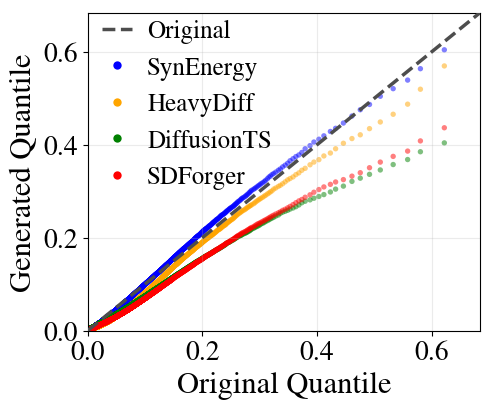

In [16]:
plot_qq_vs_ori(
    group_ori[0],
    group_heavy_cn[2],
    group_cn[4],
    group_diff[0],
    group_heavy[1],
    colors=("blue", "orange", "green", "red"),
    labels=("SynEnergy","HeavyDiff","DiffusionTS","SDForger"),
    legend_markersize = 6,
    legend_bbox_to_anchor=(-0.02, 1.05),
    save_path="../../../Analysis/Plot/Experiment/Anomaly_Visualization/Quantile–Quantile Comparison of Anomaly Energy.png",
)

## Figure 7 Anomaly Rate

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
def plot_anomaly_rate(
    ori,
    gen,
    *,
    labels=("ori", "gen"),
    colors=("#2166ac", "#1f77b4"),
    tau=0.12,
    bins=40,
    kde=True,
    figsize=(5, 4.2),
    fontsize=22,
    xlim = (0, 1),
    save_path=None,
):
    """两个输入的 anomaly_rate 边际分布图。
    示例
    ----
    plot_anomaly_rate(group_ori[0], group_heavy_cn[2], labels=("ori", "SynEnergy"))
    """
    result = compare_anomaly_distribution_multi(
        ori,
        {"gen": gen},
        tau=tau,
        store_pooled_arrays=False,
    )
    ori_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["ori"]["anomaly_rate"],
        dtype=np.float64,
    )
    gen_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["gen"]["anomaly_rate"],
        dtype=np.float64,
    )
    ori_v = ori_v[np.isfinite(ori_v)]
    gen_v = gen_v[np.isfinite(gen_v)]
    if ori_v.size == 0 or gen_v.size == 0:
        raise ValueError("anomaly_rate has no finite values.")
    lo = min(ori_v.min(), gen_v.min())
    hi = max(ori_v.max(), gen_v.max())
    if lo == hi:
        hi = lo + 1.0
    hist_bins = np.linspace(lo, hi, bins + 1)
    w1 = result["baselines"]["gen"]["sample_features"]["anomaly_rate"]["wasserstein"]
    fig, ax = plt.subplots(figsize=figsize)
    ax.hist(ori_v, bins=hist_bins, density=True, alpha=0.30, color=colors[0], label=labels[0])
    ax.hist(gen_v, bins=hist_bins, density=True, alpha=0.25, color=colors[1], label=labels[1])
    if kde:
        xs = np.linspace(lo, hi, 200)
        if ori_v.size >= 2:
            ax.plot(xs, gaussian_kde(ori_v)(xs), color=colors[0], lw=3)
        if gen_v.size >= 2:
            ax.plot(xs, gaussian_kde(gen_v)(xs), color=colors[1], lw=3)
    ax.set_xlim(xlim)
    ax.set_xlabel("Anomaly Rate", fontsize=fontsize)
    ax.set_ylabel("Density", fontsize=fontsize)
    #ax.set_title(f"anomaly_rate  (W1={w1:.4f})", fontsize=fontsize)
    ax.tick_params(labelsize=fontsize)
    ax.legend(frameon=False, fontsize=fontsize,loc="upper right",bbox_to_anchor=(1.00, 1.00))
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

In [18]:
PLOT_DIR = "../../../Analysis/Plot/Experiment/Anomaly_Visualization"

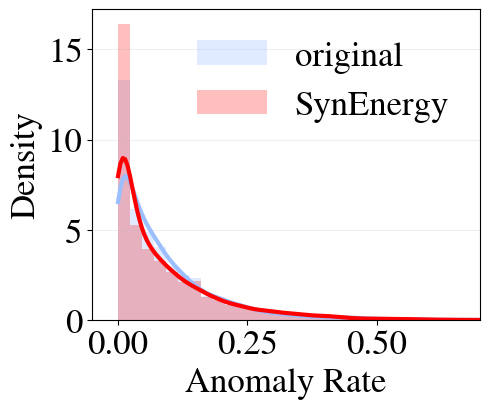

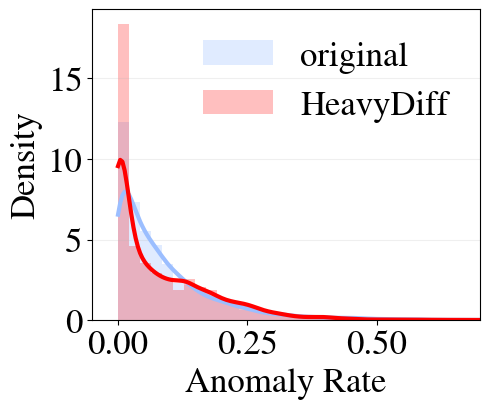

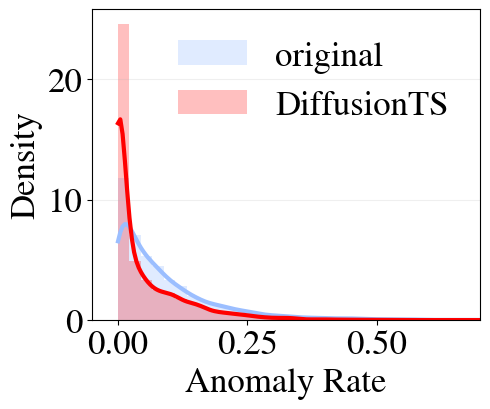

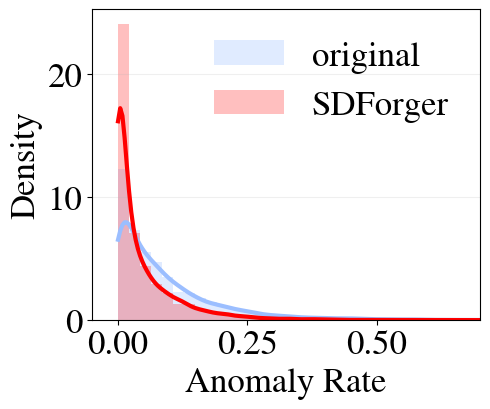

In [19]:
plot_anomaly_rate(
    group_ori[0],
    group_heavy_cn[0],
    labels=("original", "SynEnergy"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-0.05, 0.7),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_rate_SynEnergy.png"
)

plot_anomaly_rate(
    group_ori[0],
    group_cn[0],
    
    labels=("original", "HeavyDiff"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-0.05, 0.7),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_rate_HeavyDiff.png"
)

plot_anomaly_rate(
    group_ori[0],
    group_diff[0],
    labels=("original", "DiffusionTS"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-0.05, 0.7),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_rate_DiffusionTS.png"
)

plot_anomaly_rate(
    group_ori[0],
    group_heavy[0],
    labels=("original", "SDForger"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-0.05, 0.7),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_rate_SDForger.png"
)

## Figure 8 Event Count

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


def plot_event_count(
    ori,
    gen,
    *,
    labels=("ori", "gen"),
    colors=("#2166ac", "#1f77b4"),
    tau=0.12,
    bins=40,
    kde=True,
    figsize=(5, 4.2),
    fontsize=22,
    xlim=None,
    ylim=None,
    save_path=None,
):
    """两个输入的 event_count 边际分布图。

    示例
    ----
    plot_event_count(group_ori[0], group_heavy_cn[2], labels=("Original", "SynEnergy"))
    """
    result = compare_anomaly_distribution_multi(
        ori,
        {"gen": gen},
        tau=tau,
        store_pooled_arrays=False,
    )

    ori_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["ori"]["event_count"],
        dtype=np.float64,
    )
    gen_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["gen"]["event_count"],
        dtype=np.float64,
    )
    ori_v = ori_v[np.isfinite(ori_v)]
    gen_v = gen_v[np.isfinite(gen_v)]
    if ori_v.size == 0 or gen_v.size == 0:
        raise ValueError("event_count has no finite values.")

    lo = min(ori_v.min(), gen_v.min())
    hi = max(ori_v.max(), gen_v.max())
    if lo == hi:
        hi = lo + 1.0
    hist_bins = np.linspace(lo, hi, bins + 1)

    w1 = result["baselines"]["gen"]["sample_features"]["event_count"]["wasserstein"]

    fig, ax = plt.subplots(figsize=figsize)
    ax.hist(ori_v, bins=hist_bins, density=True, alpha=0.30, color=colors[0], label=labels[0])
    ax.hist(gen_v, bins=hist_bins, density=True, alpha=0.25, color=colors[1], label=labels[1])

    if kde:
        xs = np.linspace(lo, hi, 200)
        if ori_v.size >= 2:
            ax.plot(xs, gaussian_kde(ori_v)(xs), color=colors[0], lw=3)
        if gen_v.size >= 2:
            ax.plot(xs, gaussian_kde(gen_v)(xs), color=colors[1], lw=3)

    if xlim is not None:
        ax.set_xlim(xlim)
    ax.set_xlabel("Anomaly Event Count", fontsize=fontsize)
    ax.set_ylabel("Density", fontsize=fontsize)
    ax.set_ylim(ylim)
    ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4])
    # ax.set_title(f"event_count  (W1={w1:.4f})", fontsize=fontsize)
    ax.tick_params(labelsize=fontsize)
    ax.legend(
        frameon=False,
        fontsize=fontsize,
        loc="upper right",
        bbox_to_anchor=(1.00, 1.00),
    )
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

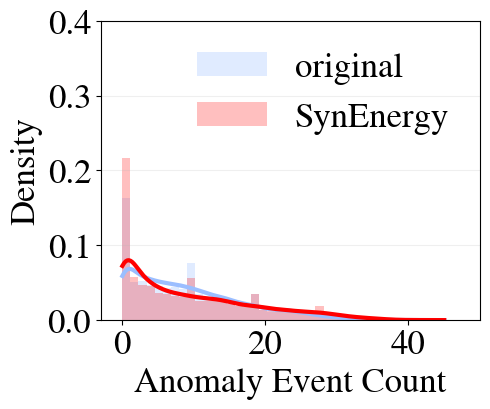

In [21]:
plot_event_count(
    group_ori[0],
    group_heavy_cn[0],
    labels=("original", "SynEnergy"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-3, 50),
    ylim=(0, 0.4),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_event_count_SynEnergy.png"
)

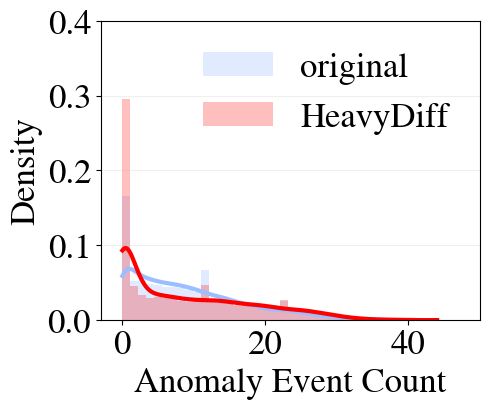

In [132]:
plot_event_count(
    group_ori[0],
    group_cn[0],
    labels=("original", "HeavyDiff"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-3, 50),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_event_count_HeavyDiff.png"
)

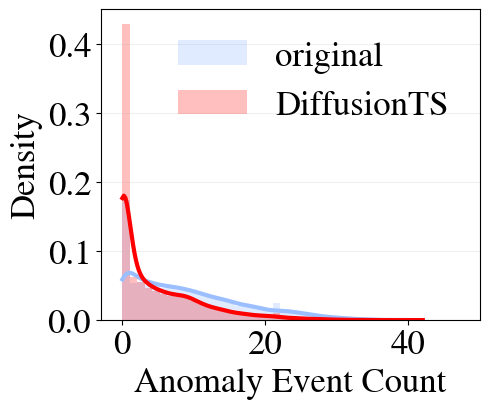

In [133]:
plot_event_count(
    group_ori[0],
    group_diff[3],
    labels=("original", "DiffusionTS"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-3, 50),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_event_count_DiffusionTS.png"
)

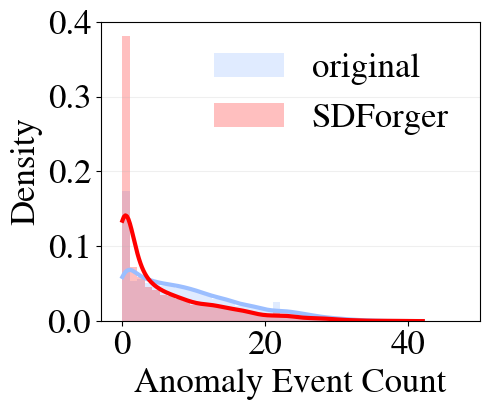

In [134]:
plot_event_count(
    group_ori[0],
    group_heavy[2],
    labels=("original", "SDForger"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(-3, 50),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_event_count_SDForger.png"
)

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


def plot_mean_abs_on_anom(
    ori,
    gen,
    *,
    labels=("ori", "gen"),
    colors=("#2166ac", "#1f77b4"),
    tau=0.12,
    bins=40,
    kde=True,
    figsize=(5, 4.2),
    fontsize=22,
    xlim=None,
    ylim=None,
    save_path=None,
):
    """两个输入的 mean_abs_on_anom 边际分布图。

    示例
    ----
    plot_mean_abs_on_anom(group_ori[0], group_heavy_cn[2], labels=("Original", "SynEnergy"))
    """
    result = compare_anomaly_distribution_multi(
        ori,
        {"gen": gen},
        tau=tau,
        store_pooled_arrays=False,
    )

    ori_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["ori"]["mean_abs_on_anom"],
        dtype=np.float64,
    )
    gen_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["gen"]["mean_abs_on_anom"],
        dtype=np.float64,
    )
    ori_v = ori_v[np.isfinite(ori_v)]
    gen_v = gen_v[np.isfinite(gen_v)]
    if ori_v.size == 0 or gen_v.size == 0:
        raise ValueError("mean_abs_on_anom has no finite values.")

    lo = min(ori_v.min(), gen_v.min())
    hi = max(ori_v.max(), gen_v.max())
    if lo == hi:
        hi = lo + 1.0
    hist_bins = np.linspace(lo, hi, bins + 1)

    w1 = result["baselines"]["gen"]["sample_features"]["mean_abs_on_anom"]["wasserstein"]

    fig, ax = plt.subplots(figsize=figsize)
    ax.hist(ori_v, bins=hist_bins, density=True, alpha=0.30, color=colors[0], label=labels[0])
    ax.hist(gen_v, bins=hist_bins, density=True, alpha=0.25, color=colors[1], label=labels[1])

    if kde:
        xs = np.linspace(lo, hi, 200)
        if ori_v.size >= 2:
            ax.plot(xs, gaussian_kde(ori_v)(xs), color=colors[0], lw=3)
        if gen_v.size >= 2:
            ax.plot(xs, gaussian_kde(gen_v)(xs), color=colors[1], lw=3)

    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)

    ax.set_xlabel("Anomaly Magnitude", fontsize=fontsize)
    ax.set_ylabel("Density", fontsize=fontsize)
    # ax.set_title(f"mean_abs_on_anom  (W1={w1:.4f})", fontsize=fontsize)
    ax.tick_params(labelsize=fontsize)
    ax.legend(
        frameon=False,
        fontsize=fontsize,
        loc="upper right",
        bbox_to_anchor=(1.05, 1.05),
    )
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

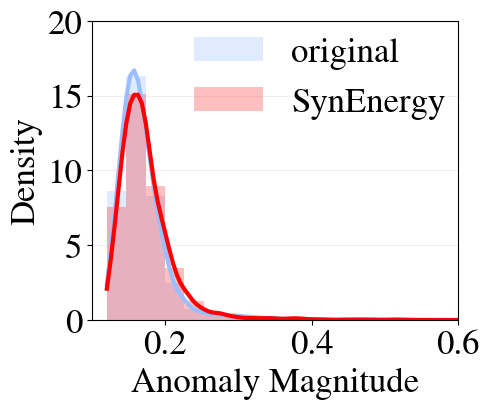

In [23]:
plot_mean_abs_on_anom(
    group_ori[0],
    group_cn[0],
    labels=("original", "SynEnergy"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(0.1, 0.6),
    ylim=(0, 20),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_magnitude_SynEnergy.png"
)

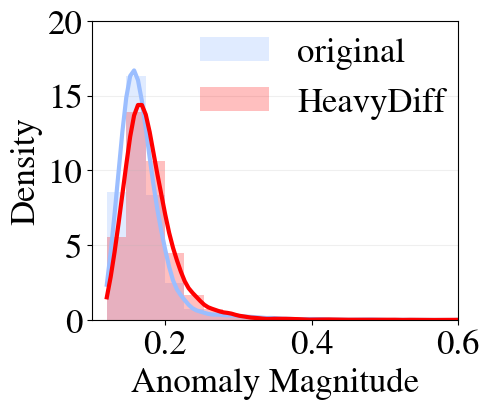

In [166]:
plot_mean_abs_on_anom(
    group_ori[0],
    group_heavy_cn[0],
    labels=("original", "HeavyDiff"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(0.1, 0.6),
    ylim=(0, 20),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_magnitude_HeavyDiff.png"
)

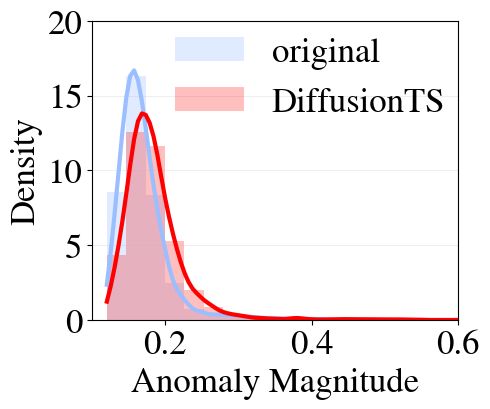

In [167]:
plot_mean_abs_on_anom(
    group_ori[0],
    group_heavy_cn[3],
    labels=("original", "DiffusionTS"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(0.1, 0.6),
    ylim=(0, 20),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_magnitude_DiffusionTS.png"
)

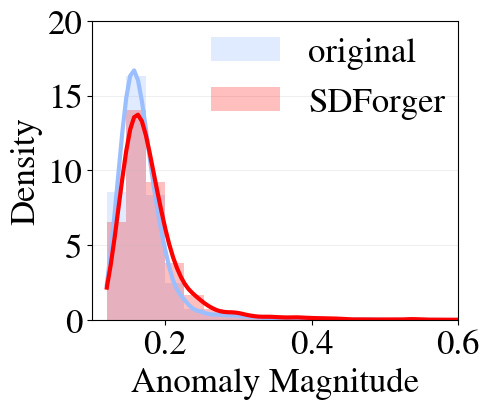

In [168]:
plot_mean_abs_on_anom(
    group_ori[0],
    group_cn[1],
    labels=("original", "SDForger"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=(0.1, 0.6),
    ylim=(0, 20),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_magnitude_SDForger.png"
)

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
def plot_anomaly_energy(
    ori,
    gen,
    *,
    labels=("ori", "gen"),
    colors=("#2166ac", "#1f77b4"),
    tau=0.12,
    bins=40,
    kde=True,
    figsize=(5, 4.2),
    fontsize=22,
    xlim=None,   # 仍用原始 energy 坐标，如 (1e-2, 1e1)
    ylim=None,
    save_path=None,
):
    """anomaly_energy：在 log10 空间估计密度，再映射回原坐标轴。"""
    result = compare_anomaly_distribution_multi(
        ori,
        {"gen": gen},
        tau=tau,
        store_pooled_arrays=False,
    )
    ori_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["ori"]["anomaly_energy"],
        dtype=np.float64,
    )
    gen_v = np.asarray(
        result["baselines"]["gen"]["per_sample"]["gen"]["anomaly_energy"],
        dtype=np.float64,
    )
    ori_v = ori_v[np.isfinite(ori_v) & (ori_v > 0)]
    gen_v = gen_v[np.isfinite(gen_v) & (gen_v > 0)]
    if ori_v.size == 0 or gen_v.size == 0:
        raise ValueError("anomaly_energy has no positive finite values.")
    # ---- 方案B：在 log10 空间做 hist / KDE ----
    ori_u = np.log10(ori_v)
    gen_u = np.log10(gen_v)
    lo_u = min(ori_u.min(), gen_u.min())
    hi_u = max(ori_u.max(), gen_u.max())
    if lo_u == hi_u:
        hi_u = lo_u + 1.0
    hist_bins_u = np.linspace(lo_u, hi_u, bins + 1)
    xs_u = np.linspace(lo_u, hi_u, 200)
    xs = 10 ** xs_u  # 画回原坐标
    fig, ax = plt.subplots(figsize=figsize)
    # 注意：hist 也在 u 空间算 density，再用同一组 bin 映射到 x=10^u
    ax.hist(
        ori_v,
        bins=10 ** hist_bins_u,
        density=True,
        alpha=0.30,
        color=colors[0],
        label=labels[0],
    )
    ax.hist(
        gen_v,
        bins=10 ** hist_bins_u,
        density=True,
        alpha=0.25,
        color=colors[1],
        label=labels[1],
    )
    # 更对齐的做法：直接画 log 空间 KDE，再经雅可比变换回 x 空间
    # f_x(x) = f_u(log10 x) / (x * ln(10))
    if kde:
        ln10 = np.log(10.0)
        if ori_u.size >= 2:
            fu = gaussian_kde(ori_u)(xs_u)
            ax.plot(xs, fu / (xs * ln10), color=colors[0], lw=3)
        if gen_u.size >= 2:
            fu = gaussian_kde(gen_u)(xs_u)
            ax.plot(xs, fu / (xs * ln10), color=colors[1], lw=3)
    ax.set_xscale("log")
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel("Anomaly Energy", fontsize=fontsize)
    ax.set_ylabel("Density", fontsize=fontsize)
    ax.tick_params(labelsize=fontsize)
    ax.legend(
        frameon=False,
        fontsize=fontsize,
        loc="upper right",
        bbox_to_anchor=(1.00, 1.00),
    )
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

In [25]:
result = compare_anomaly_distribution_multi(
    group_ori[0], {"gen": group_heavy_cn[2]}, tau=0.12
)
ori_e = result["baselines"]["gen"]["per_sample"]["ori"]["anomaly_energy"]
gen_e = result["baselines"]["gen"]["per_sample"]["gen"]["anomaly_energy"]
vals = np.concatenate([ori_e[ori_e > 0], gen_e[gen_e > 0]])

lo, hi = np.quantile(vals, [0.01, 0.99])
xlim = (lo, hi)

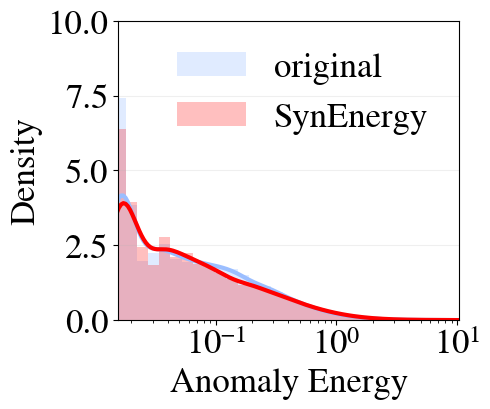

In [26]:
plot_anomaly_energy(
    group_ori[0],
    group_heavy_cn[0],
    labels=("original", "SynEnergy"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=xlim,
    ylim=(0, 10),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_energy_SynEnergy.png"
)

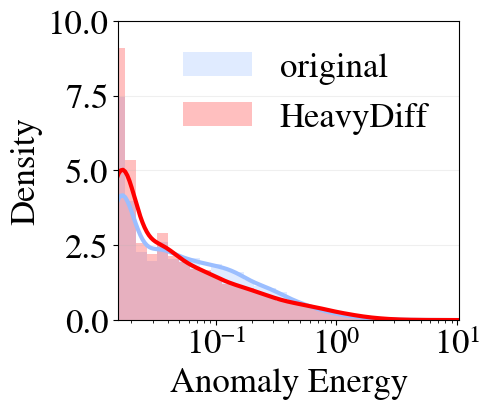

In [23]:
plot_anomaly_energy(
    group_ori[0],
    group_cn[0],
    labels=("original", "HeavyDiff"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=xlim,
    ylim=(0, 10),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_energy_HeavyDiff.png"
)

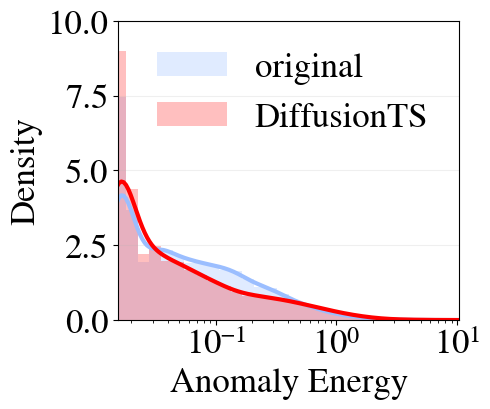

In [24]:
plot_anomaly_energy(
    group_ori[0],
    group_cn[2],
    labels=("original", "DiffusionTS"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=xlim,
    ylim=(0, 10),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_energy_DiffusionTS.png"
)

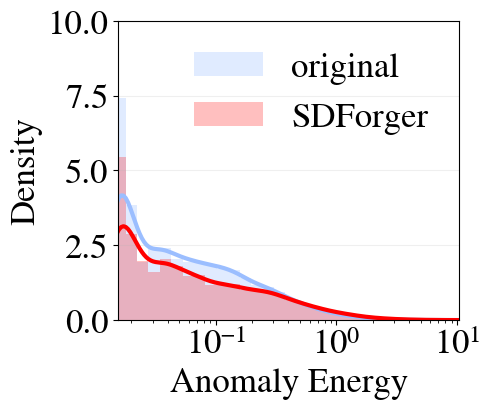

In [25]:
plot_anomaly_energy(
    group_ori[0],
    group_cn[3],
    labels=("original", "SDForger"),
    colors=("#9BBEFF","red"),
    figsize=(5, 4.2),
    xlim=xlim,
    ylim=(0, 10),
    fontsize=25,
    save_path=f"{PLOT_DIR}/anomaly_energy_SDForger.png"
)